# Retail Sales Data Analysis
**Role:** Junior Data Analyst  
**Name:** Raza Mustafa  

**Goal:** Clean the sales dataset (89,984 records, 23 features), analyze it and give insights.

## Step 1: Import libraries and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/engraamirjamil/retail-sales-dataset-for-data-preprocessing/sales_dataset_89984_records_23_features.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/engraamirjamil/retail-sales-dataset-for-data-preprocessing/sales_dataset_89984_records_23_features.csv'

## Step 2: Understand the data

In [ ]:
print("Shape:", df.shape)
df.info()

NameError: name 'df' is not defined

In [ ]:
df.describe()

NameError: name 'df' is not defined

In [ ]:
# missing values in each column
df.isnull().sum()

NameError: name 'df' is not defined

In [ ]:
# duplicate rows
print("Duplicate rows:", df.duplicated().sum())

NameError: name 'df' is not defined

In [ ]:
# check text columns for inconsistent values
for col in ['Gender', 'City', 'Customer_Segment', 'Sales_Channel', 'Payment_Method', 'Marketing_Channel']:
    print(col)
    print(df[col].value_counts())
    print('----------------')

Gender


NameError: name 'df' is not defined

**Problems found:**
- Many columns have missing values (Customer_Rating has the most).
- 65 duplicate rows.
- Same category written in different ways, e.g. `Male`, `male`, ` MALE `, `M`.
- Invalid values like negative Quantity and Unit_Price, Age 0 or 132, Discount above 100%, Rating -1 or 7.
- Some dates are in a different format or written as "not recorded".

## Step 3: Remove duplicates

In [ ]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

NameError: name 'df' is not defined

## Step 4: Fix inconsistent categories
First remove extra spaces and make the text Title Case, then fix short forms.

In [ ]:
text_cols = ['Gender', 'City', 'Customer_Segment', 'Sales_Channel', 'Payment_Method', 'Marketing_Channel']

for col in text_cols:
    df[col] = df[col].str.strip().str.title()

df['Gender'] = df['Gender'].replace({'M': 'Male', 'F': 'Female'})
df['Sales_Channel'] = df['Sales_Channel'].replace({'E-Commerce': 'Online', 'Retail': 'Retail Store'})
df['Payment_Method'] = df['Payment_Method'].replace({'Cod': 'Cash On Delivery', 'Wallet': 'Digital Wallet'})
df['Marketing_Channel'] = df['Marketing_Channel'].replace({'Social': 'Social Media', 'Sms': 'SMS'})

for col in text_cols:
    print(col, df[col].unique())

NameError: name 'df' is not defined

## Step 5: Fix dates

In [ ]:
# most dates are yyyy-mm-dd, some are dd-mm-yyyy
dates1 = pd.to_datetime(df['Order_Date'], format='%Y-%m-%d', errors='coerce')
dates2 = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y', errors='coerce')
df['Order_Date'] = dates1.fillna(dates2)

print("Dates that could not be fixed:", df['Order_Date'].isnull().sum())

# remove the few rows with wrong dates
df = df.dropna(subset=['Order_Date'])

NameError: name 'df' is not defined

## Step 6: Handle invalid values
Values that are not possible are changed to NaN, then filled in the next step.

In [ ]:
df.loc[(df['Customer_Age'] < 18) | (df['Customer_Age'] > 90), 'Customer_Age'] = np.nan
df.loc[df['Unit_Price'] <= 0, 'Unit_Price'] = np.nan
df.loc[df['Quantity'] <= 0, 'Quantity'] = np.nan
df.loc[(df['Discount_Percent'] < 0) | (df['Discount_Percent'] > 100), 'Discount_Percent'] = np.nan
df.loc[(df['Customer_Rating'] < 1) | (df['Customer_Rating'] > 5), 'Customer_Rating'] = np.nan

NameError: name 'df' is not defined

## Step 7: Handle missing values
- Number columns → fill with **median** (not affected by outliers)
- Text columns → fill with **mode** (most common value)

In [ ]:
num_cols = ['Customer_Age', 'Unit_Price', 'Quantity', 'Discount_Percent',
            'Shipping_Cost', 'Customer_Rating', 'Profit_Margin']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = ['Gender', 'City', 'Customer_Segment', 'Sales_Channel', 'Product_Category',
            'Product_Name', 'Payment_Method', 'Order_Status', 'Marketing_Channel']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Total missing values now:", df.isnull().sum().sum())

NameError: name 'df' is not defined

## Step 8: Handle outliers (IQR method)
Very big values are capped at the upper limit instead of deleting the rows.

NameError: name 'df' is not defined

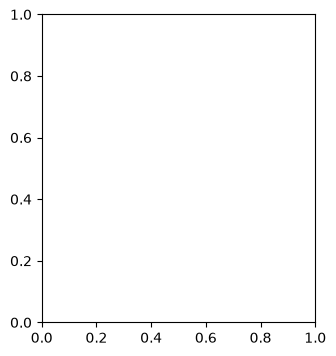

In [ ]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(['Unit_Price', 'Quantity', 'Sales_Amount']):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
for col in ['Unit_Price', 'Quantity', 'Sales_Amount']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "outliers:", outliers)
    df[col] = df[col].clip(lower, upper)

NameError: name 'df' is not defined

In [ ]:
print("Final shape:", df.shape)
df.describe()

NameError: name 'df' is not defined

## Step 9: Analysis

In [ ]:
print("Total Sales:", round(df['Sales_Amount'].sum(), 2))
print("Total Orders:", df['Order_ID'].nunique())
print("Average Order Value:", round(df['Sales_Amount'].mean(), 2))
print("Average Rating:", round(df['Customer_Rating'].mean(), 2))

NameError: name 'df' is not defined

In [ ]:
# sales by product category
cat_sales = df.groupby('Product_Category')['Sales_Amount'].sum().sort_values(ascending=False)
print(cat_sales)

cat_sales.plot(kind='bar', figsize=(8, 4), color='teal')
plt.title('Sales by Product Category')
plt.ylabel('Sales')
plt.show()

NameError: name 'df' is not defined

In [ ]:
# sales by region
region_sales = df.groupby('Region')['Sales_Amount'].sum().sort_values(ascending=False)
print(region_sales)

region_sales.plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6))
plt.title('Sales Share by Region')
plt.ylabel('')
plt.show()

NameError: name 'df' is not defined

In [ ]:
# top 10 cities
city_sales = df.groupby('City')['Sales_Amount'].sum().sort_values(ascending=False).head(10)
city_sales.plot(kind='barh', figsize=(8, 4), color='orange')
plt.title('Top 10 Cities by Sales')
plt.gca().invert_yaxis()
plt.show()

NameError: name 'df' is not defined

In [ ]:
# monthly sales trend
df['Month'] = df['Order_Date'].dt.strftime('%Y-%m')
monthly = df.groupby('Month')['Sales_Amount'].sum()

monthly.plot(figsize=(12, 4), marker='o')
plt.xticks(range(len(monthly)), monthly.index, rotation=90)
plt.title('Monthly Sales Trend')
plt.ylabel('Sales')
plt.show()

NameError: name 'df' is not defined

NameError: name 'df' is not defined

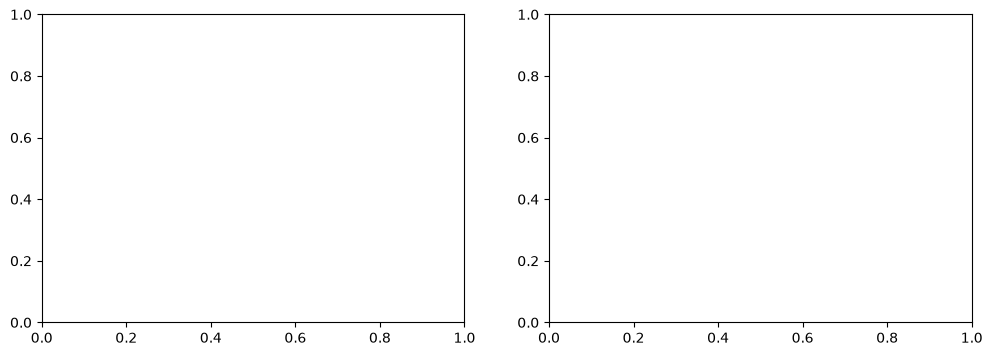

In [ ]:
# sales channel and payment method
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['Sales_Channel'].value_counts().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Orders by Sales Channel')
df['Payment_Method'].value_counts().plot(kind='bar', ax=ax[1], color='green')
ax[1].set_title('Orders by Payment Method')
plt.tight_layout()
plt.show()

In [ ]:
# average profit margin by category
profit = df.groupby('Product_Category')['Profit_Margin'].mean().sort_values(ascending=False)
print(profit.round(2))

NameError: name 'df' is not defined

In [ ]:
# return rate by category
return_rate = df.groupby('Product_Category')['Return_Flag'].apply(lambda x: (x == 'Yes').mean() * 100)
print(return_rate.sort_values(ascending=False).round(2))

NameError: name 'df' is not defined

In [ ]:
# marketing channel performance
print(df.groupby('Marketing_Channel')['Sales_Amount'].sum().sort_values(ascending=False))

NameError: name 'df' is not defined

In [ ]:
# correlation between numeric columns
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Customer_Age', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Shipping_Cost',
                'Customer_Rating', 'Sales_Amount', 'Profit_Margin']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

NameError: name 'df' is not defined

<Figure size 800x600 with 0 Axes>

## Step 10: Key Insights

1. **Total sales** are about **Rs 780 million** from about 89,900 orders, with an average order value of around **Rs 8,676**.
2. **Electronics** is the top category (about **29%** of sales), followed by Clothing and Home & Kitchen. Stationery sells the least.
3. **Punjab** gives more than half of all sales (**~51%**), then Sindh (~26%). Balochistan is the lowest (~3.5%).
4. **Karachi** and **Lahore** are the top cities, together almost **41%** of sales.
5. **Online** is the biggest sales channel (~47% of orders).
6. **Cash on Delivery** is still the most used payment method (~38%).
7. Sales are highest in **November and December** and lowest in **February**.
8. **Search** and **Social Media** bring the most sales among marketing channels.
9. Electronics has the **lowest profit margin (~16%)**, while Beauty and Stationery have the highest (~31%).
10. **Clothing and Electronics** have the highest return rate (~7%).
11. Higher discount is linked with lower profit margin (correlation about -0.32).

## Step 11: Recommendations for Management

- Focus more on **online** sales and on **Search & Social Media** ads, because they bring the most sales.
- Prepare more stock and offers for **November–December**, and run promotions in **February** to increase low sales.
- Electronics sells the most but earns the least profit, so **review its prices and discounts**.
- Promote **Beauty** products more because they have high profit.
- Reduce returns in **Clothing** (better size guide and pictures) and **Electronics** (better product details).
- Grow sales in **KPK and Balochistan**, where sales are low.
- Encourage **digital payments** (small discount) to reduce Cash on Delivery problems.
- Improve data entry so the same values are not written in different ways.

## Conclusion
The dataset had missing values, duplicates, inconsistent categories, invalid values and outliers. After cleaning, the data was analyzed by category, region, city, channel, payment method and time. The results show which products, areas and channels perform best, and these insights can help management make better business decisions.